In [86]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import netCDF4 as nc
import scipy as sp

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [87]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../src")   # path from notebooks/ to src/

import windtools as wt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Check the data and preliminary analysis

In [3]:
ds = xr.open_dataset("../data/raw/hamburg_winds.nc")
ds

<xarray.Dataset> Size: 3MB
Dimensions:     (valid_time: 184080)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 1MB 2005-01-01 ... 2025-12-31T23:...
    latitude    float64 8B ...
    longitude   float64 8B ...
Data variables:
    u100        (valid_time) float32 736kB ...
    v100        (valid_time) float32 736kB ...
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2024-09-02T04:48 GRIB to CDM+CF via cfgrib-0.9.1...
    institution:             European Centre for Medium-Range Weather Forecasts

## change valid_time to time 

In [11]:
ds = ds.assign_coords(valid_time=pd.to_datetime(ds["valid_time"].values))
ds = ds.rename({"valid_time": "time"})

## convert to pandas dataframe

In [16]:
df = ds[["u100", "v100"]].to_dataframe()[["u100", "v100"]]
df.groupby(df.index.year).size()

time
2005    8760
2006    8760
2007    8760
2008    8784
2009    8760
2010    8760
2011    8760
2012    8784
2013    8760
2014    8760
2015    8760
2016    8784
2017    8760
2018    8760
2019    8760
2020    8784
2021    8760
2022    8760
2023    8760
2024    8784
2025    8760
dtype: int64

## Wind speed and direction

In [18]:
wind_speed = np.hypot(df["u100"], df["v100"])

In [19]:
wind_direction = (np.arctan2(df["v100"], df["u100"]) * 180 / np.pi) % 360

## check if mean wind speed between 6-8 m/s

In [23]:
mean_wind = np.mean(wind_speed)
print(mean_wind)

6.3614407


## Check the wind speed distribution

Hourly wind speeds are skewed: many moderate values, few very high ones, and never negative. The standard model is the Weibull distribution:

$$
f(v) = \frac{k}{A}
\left(\frac{v}{A}\right)^{k-1}
\exp\left[-\left(\frac{v}{A}\right)^k\right],
\qquad v \ge 0
$$

A (scale) sets the typical speed, about 1.13 × the mean speed when k ≈ 2.
k (shape) sets the spread. A small k means variable winds; a large k means steady winds. Mid-latitude sites typically have k ≈ 1.8–2.5. k = 2 is the special case called the Rayleigh distribution.

weibull_min.fit(wind_speed, floc=0) fixes the location parameter at 0, because wind speed starts at zero, and estimates k and A.

In [28]:
sp.stats.weibull_min.fit(wind_speed, floc=0)

(np.float64(2.4701682381960355), 0, np.float64(7.162065182897501))

The histogram summarizes the wind speeds you actually observed. Each bar counts observations within a speed range, so taller bars mean that range occurred more often. With density=True, the y-axis is probability density rather than raw counts; the total area of the bars is approximately 1.

The Weibull curve is a smooth statistical model fitted to those observations. It shows the distribution shape the model estimates for wind speeds, based on the fitted shape (k) and scale (A) parameters.

Comparing them helps you assess whether a Weibull model describes your observed wind-speed pattern reasonably well. A close match suggests it captures the overall distribution; mismatches show where it fits less well.

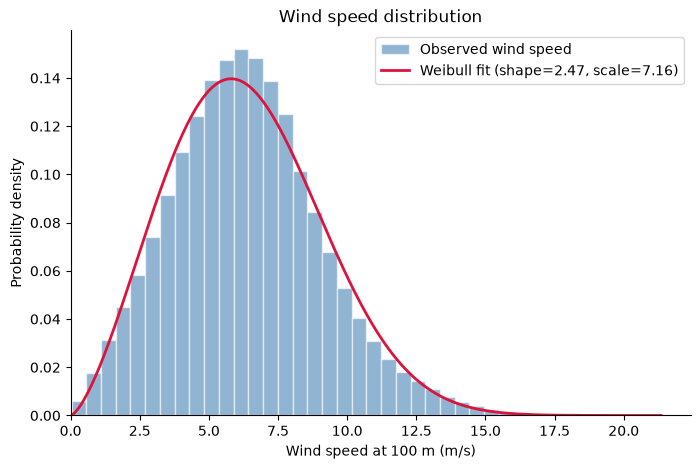

In [88]:
ws = wind_speed.dropna()
shape, loc, scale = sp.stats.weibull_min.fit(ws, floc=0)

x = np.linspace(0, ws.max(), 300)

plt.figure(figsize=(8, 5))
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(top=False, right=False)
plt.hist(ws, bins=40, density=True, alpha=0.6, edgecolor="white",
         label="Observed wind speed", color="steelblue")
plt.plot(
    x,
    sp.stats.weibull_min.pdf(x, shape, loc=loc, scale=scale),
    linewidth=2,
    label=f"Weibull fit (shape={shape:.2f}, scale={scale:.2f})", color="crimson"
)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
plt.xlabel("Wind speed at 100 m (m/s)")
plt.ylabel("Probability density")
plt.title("Wind speed distribution")
plt.legend()
plt.savefig(FIGURES_DIR / "wind_speed_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## Plot monthly wind speed

Plotting the monthly wind speed is to check the seasonality. For example, if winds are lower in summer

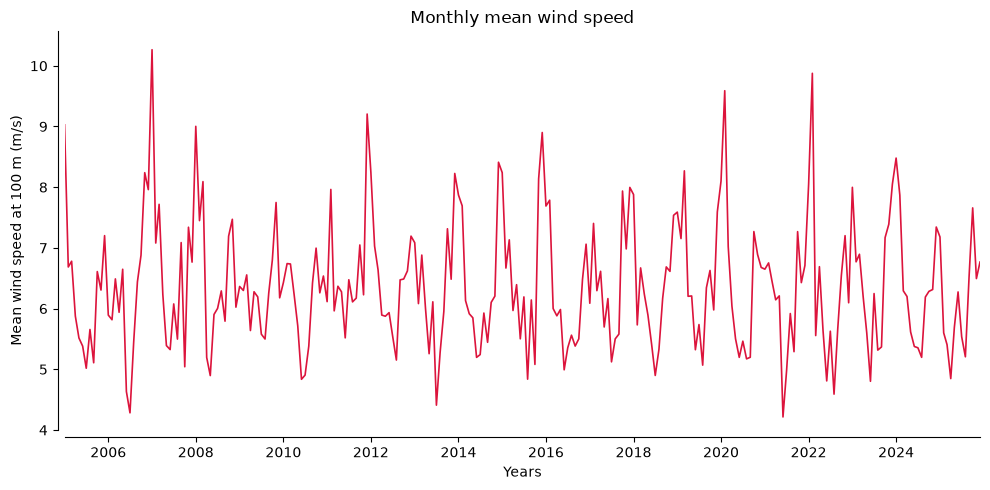

In [89]:
monthly_wind_speed = wind_speed.resample("MS").mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_wind_speed.index, monthly_wind_speed, linewidth=1.2, color="crimson")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_position(("outward", 5))
ax.spines["left"].set_position(("outward", 5))
ax.set_ylim(bottom=4)
ax.set_xlim(left=monthly_wind_speed.index.min(), right=monthly_wind_speed.index.max())
ax.set_xlabel("Years")
ax.set_ylabel("Mean wind speed at 100 m (m/s)")
ax.set_title("Monthly mean wind speed")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "monthly_mean_wind_speed.png", dpi=300, bbox_inches="tight")
plt.show()

# Power output analysis

## Power curve

The power curve describes how the modeled turbine’s output changes with wind speed. Here, output is zero below the 3 m/s cut-in speed, rises to full output at 12 m/s, stays at full output until the 25 m/s cut-out speed, and then drops to zero.

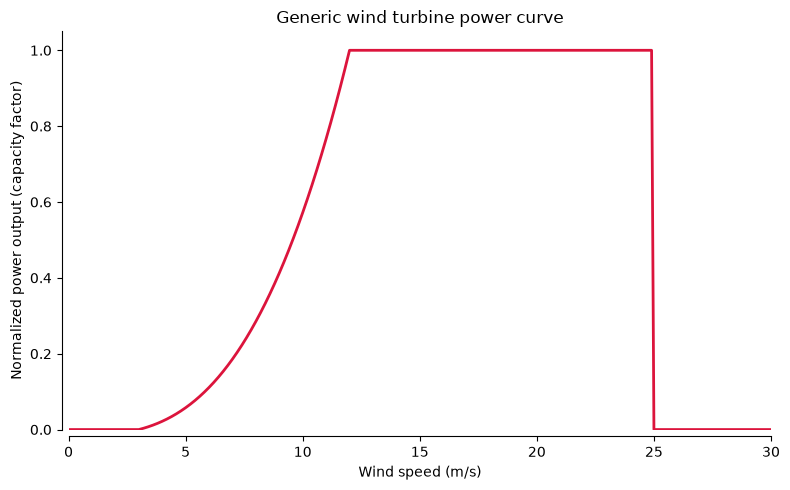

In [90]:
wind_speeds = np.linspace(0, 30, 301)
power_output = wt.power_curve(
    ws=wind_speeds,
    cut_in=3,
    rated=12,
    cut_out=25,
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(wind_speeds, power_output, color="crimson", linewidth=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_position(("outward", 5))
ax.spines["left"].set_position(("outward", 5))
ax.set_xlim(0, 30)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Wind speed (m/s)")
ax.set_ylabel("Normalized power output (capacity factor)")
ax.set_title("Generic wind turbine power curve")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "generic_power_curve.png", dpi=300, bbox_inches="tight")
plt.show()

## Capacity factor

The capacity factor applies that curve to each observed wind-speed value. It expresses modeled output as a fraction of rated output: 0 means no output, 1 means full output, and values between them mean partial output. Its average over time estimates how much of the turbine’s rated capacity would be produced on average under the assumed curve.

Both the power curve and capacity factor are model-based estimates, not actual turbine measurements. Their relevance depends on whether the assumed cut-in, rated, and cut-out speeds resemble the turbine you care about.

In [53]:
valid_wind_speed = wind_speed.dropna()
wind_data = pd.DataFrame({"ws100": valid_wind_speed})
wind_data = wt.add_capacity_factor(
    wind_data,
    cut_in=3,
    rated=12,
    cut_out=25,
)
capacity_factor = wind_data["cf"]

Mean capacity factor: 0.211 (21.1%)


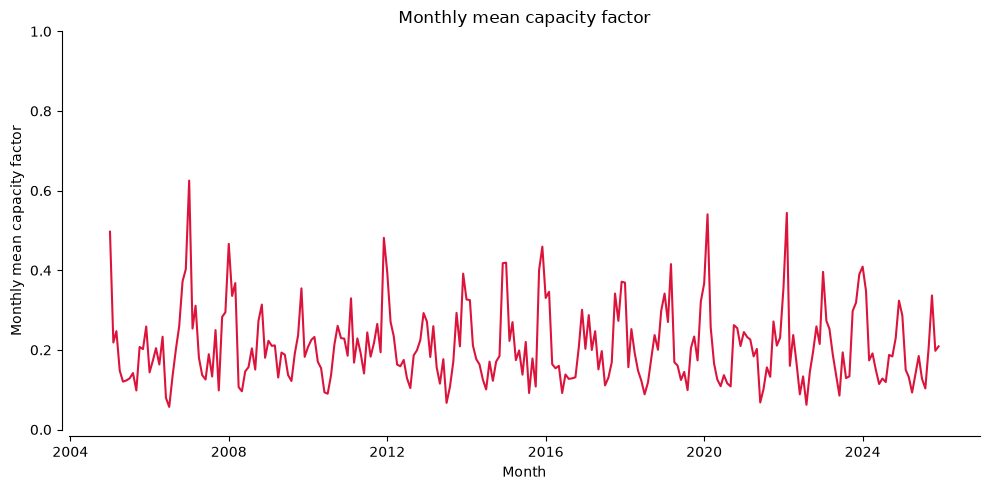

In [91]:
mean_capacity_factor = capacity_factor.mean()
print(f"Mean capacity factor: {mean_capacity_factor:.3f} ({mean_capacity_factor:.1%})")

monthly_capacity_factor = capacity_factor.resample("MS").mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_capacity_factor.index, monthly_capacity_factor, color="crimson")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_position(("outward", 5))
ax.spines["left"].set_position(("outward", 5))
ax.set_ylim(0, 1)
ax.set_xlabel("Month")
ax.set_ylabel("Monthly mean capacity factor")
ax.set_title("Monthly mean capacity factor")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "monthly_mean_capacity_factor.png", dpi=300, bbox_inches="tight")
plt.show()

## create a dataframe 

In [58]:
df["ws100"] = np.hypot(df["u100"], df["v100"])
df["wd100"] = np.degrees(np.arctan2(-df["u100"], -df["v100"])) % 360
df["cf"] = wt.power_curve(df["ws100"])

df.to_csv("../data/processed/hamburg_hourly.csv", index_label="time")

# Low wind events

A low-wind event is a continuous period when the modeled capacity factor stays below 10% for at least 48 hours.

The event table reports when each low-wind period starts and ends, how many hours it lasts, and its average capacity factor. Together, those results show how often prolonged periods of very low modeled turbine output occur and how severe or long they are. This can help assess potential periods of reduced wind generation.

It’s based on the assumed turbine curve applied to ERA5 wind at 100 m, so it’s an estimate for this dataset and location, not a record of actual turbine output or a measure of the whole electricity system.


In [83]:
low_wind = wt.find_low_wind_events(df["cf"], threshold=0.10, min_hours=48)

In [66]:
below = df["cf"] < 0.10

In [67]:
run_id = (below != below.shift()).cumsum()   # new number every time the state flips
runs = df["cf"][below].groupby(run_id[below])
events = pd.DataFrame({
    "start": runs.apply(lambda s: s.index[0]),
    "duration_h": runs.size(),
    "mean_cf": runs.mean(),
})
events = events[events["duration_h"] >= 48]

In [68]:
events

,start,duration_h,mean_cf
cf,,,
11,2005-01-26 11:00:00,81,0.009525
13,2005-02-03 03:00:00,54,0.041107
39,2005-02-23 17:00:00,69,0.032535
113,2005-04-11 15:00:00,56,0.024387
141,2005-04-29 08:00:00,59,0.006420
...,...,...,...
11127,2025-08-10 17:00:00,48,0.021304
11139,2025-08-17 02:00:00,61,0.007165
11269,2025-11-07 00:00:00,93,0.017150


Low-wind event statistics. Using the event definition above, this cell summarizes periods when the modeled capacity factor is below 10% for at least 48 consecutive hours. It reports the total number of qualifying events, the mean, minimum, and maximum number of events per year, the median and longest event durations, and the start time of the longest event. It also estimates the percentage of recorded hours that fell within qualifying events. The hourly-share calculation assumes each row in the dataset represents one hour. These results depend on the selected capacity-factor threshold and minimum event duration.

In [78]:
threshold = 0.10
events = wt.find_low_wind_events(
    df["cf"],
    threshold=threshold,
    min_hours=48,
)

years = pd.Index(df.index.year.unique()).sort_values()
annual_event_counts = (
    events.assign(year=events["start"].dt.year)
    .groupby("year")
    .size()
    .reindex(years, fill_value=0)
)

total_events = len(events)
mean_events_per_year = annual_event_counts.mean()
min_events_per_year = annual_event_counts.min()
max_events_per_year = annual_event_counts.max()

if total_events:
    median_duration_h = events["duration_h"].median()
    longest_event = events.loc[events["duration_h"].idxmax()]
    longest_duration_h = longest_event["duration_h"]
    longest_event_start = longest_event["start"]
    event_hour_share = events["duration_h"].sum() / len(df) * 100
else:
    median_duration_h = np.nan
    longest_duration_h = np.nan
    longest_event_start = pd.NaT
    event_hour_share = 0.0

print(f"Total qualifying events: {total_events}")
print(
    "Events per year: "
    f"mean={mean_events_per_year:.2f}, "
    f"minimum={min_events_per_year}, maximum={max_events_per_year}"
)
print(f"Median duration: {median_duration_h:.1f} hours")
print(f"Longest duration: {longest_duration_h:.1f} hours")
print(f"Longest event started: {longest_event_start}")
print(f"Share of recorded hours inside events: {event_hour_share:.2f}%")

Total qualifying events: 336
Events per year: mean=16.00, minimum=11, maximum=23
Median duration: 66.0 hours
Longest duration: 257.0 hours
Longest event started: 2017-01-15 10:00:00
Share of recorded hours inside events: 13.31%


These three plots show how often low-wind events occur, when they start, and how long they last. Here, an event means capacity factor stays below 10% for at least 48 hours.

- **Events per year:** Each bar counts qualifying events that started in that year. A zero means no qualifying event started that year.
- **Seasonality:** Each bar shows the average number of events starting in that month per year. For example, 0.5 means one event started in that month for every two years, on average.
- **Duration distribution:** Each bar counts how many events lasted within a given range of days.

The results depend on the chosen 10% threshold and 48-hour minimum duration.

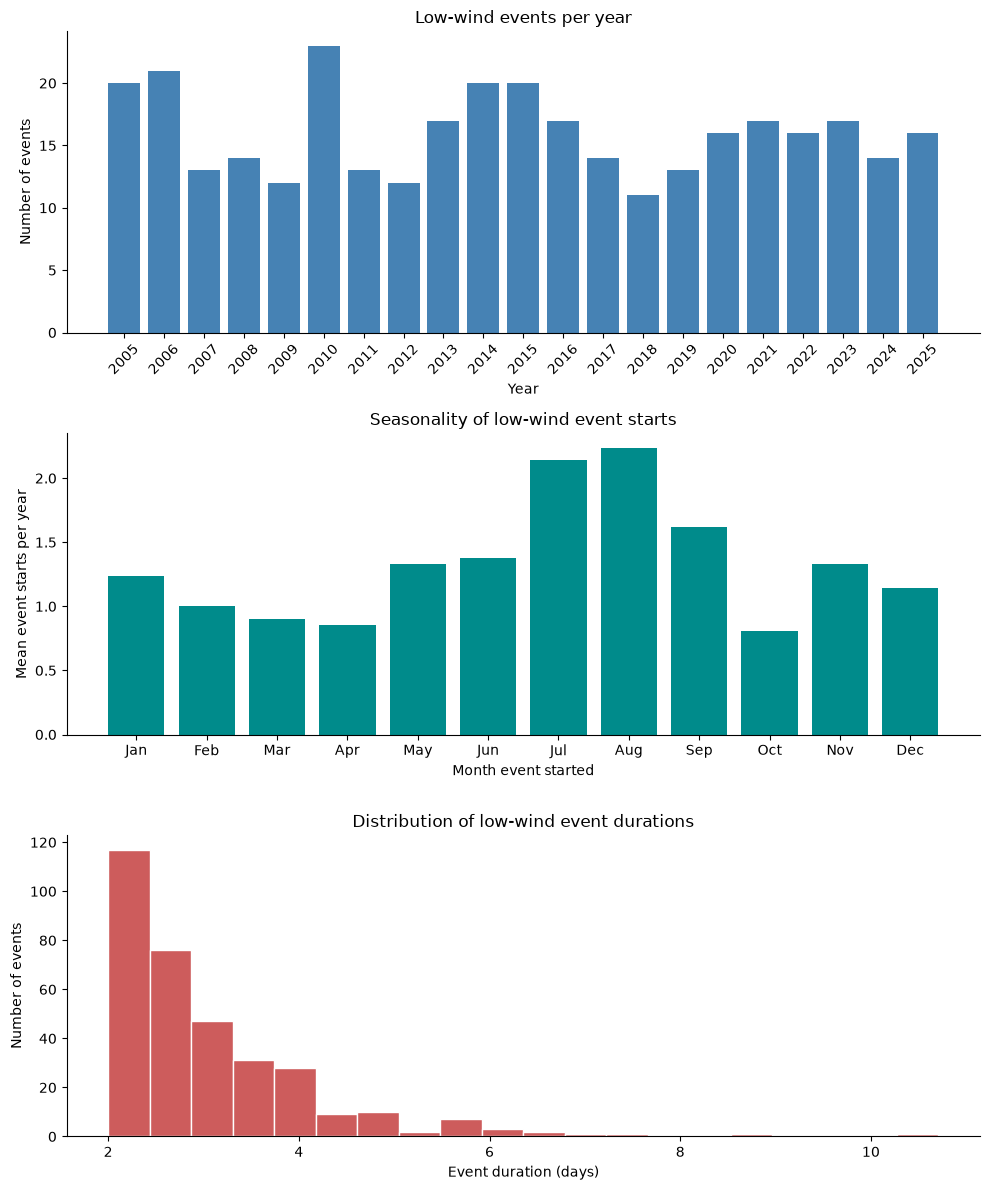

In [92]:
event_years = pd.Index(df.index.year.unique()).sort_values()
events_per_year = (
    events.assign(year=events["start"].dt.year)
    .groupby("year")
    .size()
    .reindex(event_years, fill_value=0)
)
events_per_month_per_year = (
    events["start"].dt.month.value_counts()
    .reindex(range(1, 13), fill_value=0)
    .sort_index()
    / len(event_years)
)
event_duration_days = events["duration_h"] / 24
month_labels = pd.date_range("2000-01-01", periods=12, freq="MS").strftime("%b")

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

axes[0].bar(events_per_year.index, events_per_year.values, color="steelblue")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of events")
axes[0].set_title("Low-wind events per year")
axes[0].set_xticks(events_per_year.index)
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(month_labels, events_per_month_per_year.values, color="darkcyan")
axes[1].set_xlabel("Month event started")
axes[1].set_ylabel("Mean event starts per year")
axes[1].set_title("Seasonality of low-wind event starts")

axes[2].hist(event_duration_days, bins=20, color="indianred", edgecolor="white")
axes[2].set_xlabel("Event duration (days)")
axes[2].set_ylabel("Number of events")
axes[2].set_title("Distribution of low-wind event durations")

for axis in axes:
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "low_wind_event_summary.png", dpi=300, bbox_inches="tight")
plt.show()

# Return period of low-wind events

Each dot represents one year. Its y-value is that year's longest qualifying low-wind event, measured in days. Years with no qualifying event have a duration of zero.

To estimate how unusual each duration is, the yearly maximum durations are sorted from longest to shortest. The longest gets rank 1, the second-longest rank 2, and so on. The return period is calculated as:

$$
T = \frac{n+1}{r}
$$

Here, $n$ is the number of years in the dataset and $r$ is the duration's rank. For example, with 20 years of data, the longest duration has an estimated return period of $(20+1)/1 = 21$ years; the second-longest has $(20+1)/2 = 10.5$ years.

A larger return period means a longer annual event that ranked as rarer in this dataset. It does **not** mean the event happens on a regular schedule or will next occur exactly after that many years. These are empirical estimates based on the years available and the chosen event definition (capacity factor below 10% for at least 48 hours). The x-axis is logarithmic, so equal spacing represents multiplying the return period, not adding a fixed number of years.

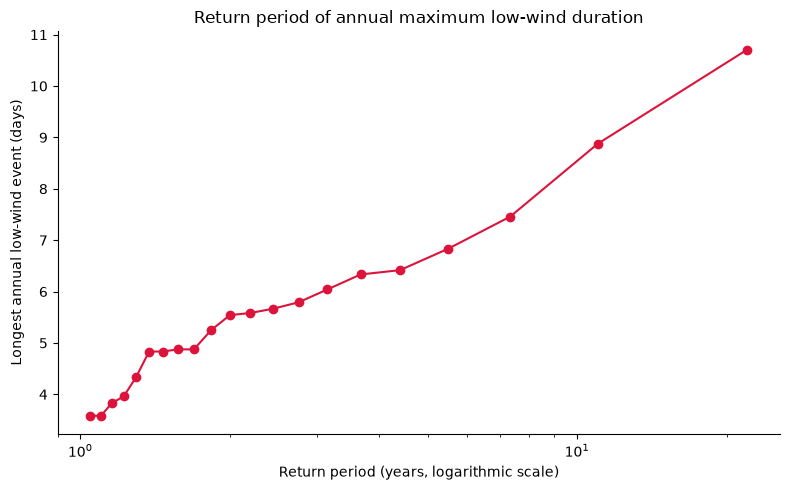

In [93]:
annual_max_duration_h = (
    events.groupby(events["start"].dt.year)["duration_h"]
    .max()
    .reindex(event_years, fill_value=0)
)
return_periods = (
    annual_max_duration_h.sort_values(ascending=False)
    .reset_index(drop=True)
    .rename("duration_h")
    .to_frame()
)
return_periods["rank"] = np.arange(1, len(return_periods) + 1)
number_of_years = len(return_periods)
return_periods["return_period_years"] = (
    (number_of_years + 1) / return_periods["rank"]
)
return_periods["duration_days"] = return_periods["duration_h"] / 24
return_periods = return_periods.sort_values("return_period_years")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    return_periods["return_period_years"],
    return_periods["duration_days"],
    marker="o",
    color="crimson",
)
ax.set_xscale("log")
ax.set_xlabel("Return period (years, logarithmic scale)")
ax.set_ylabel("Longest annual low-wind event (days)")
ax.set_title("Return period of annual maximum low-wind duration")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
#ax.grid(axis="both", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "low_wind_return_period.png", dpi=300, bbox_inches="tight")
plt.show()

# Sensitivity to the low-wind event definition

This table shows how the **average number of events per year** changes when we change the definition of a low-wind event. Rows give the capacity-factor threshold; columns give the minimum event duration. Each table value is the average annual count across all years in the dataset, including years with zero qualifying events.

For example, the value at **10% CF** and **48 h** is the average number of events per year when capacity factor is below 10% for at least 48 hours. A decimal value is possible because it is an average across years, not a count for one specific year.

A higher CF threshold classifies more periods as low-wind, so event counts tend to rise. A longer minimum duration excludes shorter periods, so counts tend to fall. Comparing the table shows how strongly the reported frequency depends on these choices.

In [82]:
thresholds = [0.05, 0.10, 0.15]
minimum_durations = [24, 48, 72]
sensitivity = pd.DataFrame(
    index=pd.Index(thresholds, name="Capacity factor threshold"),
    columns=pd.Index(minimum_durations, name="Minimum duration (hours)"),
    dtype=float,
)
years_in_data = pd.Index(df.index.year.unique()).sort_values()

for threshold_value in thresholds:
    for minimum_hours in minimum_durations:
        sensitivity_events = wt.find_low_wind_events(
            df["cf"],
            threshold=threshold_value,
            min_hours=minimum_hours,
        )
        counts_by_year = (
            sensitivity_events["start"].dt.year.value_counts()
            .reindex(years_in_data, fill_value=0)
        )
        sensitivity.loc[threshold_value, minimum_hours] = counts_by_year.mean()

sensitivity.columns = [f"{hours} h" for hours in minimum_durations]
sensitivity.index = [f"{threshold:.0%}" for threshold in thresholds]
sensitivity.index.name = "CF threshold"
sensitivity.columns.name = "Minimum event duration"
sensitivity.round(2)

Minimum event duration,24 h,48 h,72 h
CF threshold,,,
5%,26.52,5.00,1.38
10%,50.43,16.00,5.76
15%,62.62,28.86,13.52
